# 05 - Mesurer les écarts de gravité et leur incertitude

Le notebook 04 a montré des différences descriptives de gravité selon l'âge, la catégorie
d'usager, la lumière et l'agglomération. Nous allons maintenant en mesurer l'ampleur et
examiner leur incertitude sous un schéma de rééchantillonnage explicite.

**Notre objectif : estimer des probabilités conditionnelles, comparer des proportions et
construire des intervalles qui respectent le regroupement des usagers par accident.**

La période reste **2019-2022 en France métropolitaine, Corse comprise**. Les fichiers de
2023 et 2024 ne participent pas à ces calculs. Les comparaisons prolongent l'exploration
précédente : elles sont exploratoires, sans interprétation causale ni statut de tests
confirmatoires annoncés avant l'observation des données.

Nous commencerons par définir les quantités étudiées, puis comparerons quatre situations,
expliquerons le bootstrap sur un exemple fictif, calculerons les intervalles et relirons
les résultats par année et pour les décès seuls.


## 1. Définir la probabilité étudiée

Pour un usager dont la gravité est connue, nous définissons :

$$
Y = \begin{cases}
1 & \text{si l'usager est tué ou hospitalisé, soit grav dans \{2,3\},}\\
0 & \text{si l'usager est indemne ou légèrement blessé, soit grav dans \{1,4\}.}
\end{cases}
$$

Pour un usager tiré au hasard dans cette population, $Y$ est une variable de Bernoulli.
Si sa probabilité de succès vaut $p$, alors $E(Y)=p$ et $\mathrm{Var}(Y)=p(1-p)$.
Cela n'impose pas l'indépendance entre les usagers d'un même accident.

Notons $S$ le périmètre : accident corporel enregistré en métropole en 2019-2022 et
gravité connue. Pour un groupe $G$, nous estimons :

$$
p_G=P(Y=1\mid G,S), \qquad
\widehat p_G=\frac{\text{usagers de }G\text{ avec }Y=1}
{\text{usagers de }G\text{ dont la gravité est connue}}.
$$

Le conditionnement est essentiel : nous décrivons la gravité parmi les usagers enregistrés,
pas la probabilité d'accident lors d'un trajet. Une gravité inconnue ne reçoit aucune des
deux valeurs de $Y$. Les limites de collecte et d'interprétation de l'hospitalisation
restent celles exposées dans les notebooks précédents.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option("display.max_columns", 15)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "savefig.facecolor": "white"})
BLUE, ORANGE, GREY = "#285E7E", "#C46B32", "#78868F"
TRAIN_YEARS = [2019, 2020, 2021, 2022]
PRIMARY = "cible_deces_hospitalisation"
B = 2_000
SEED = 20261016
EXPORT_RESULTS = True
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}")


Python 3.12.3 | pandas 3.0.6 | numpy 2.5.4


### Charger uniquement la période d'apprentissage

Nous reprenons le CSV et le schéma du notebook 03, en sélectionnant les années lors de
la lecture par blocs. L'état d'un autre notebook n'est pas nécessaire. La cible « décès
seul » vaut 1 pour `grav = 2` et 0 pour les trois autres modalités connues ; elle reste
manquante lorsque `grav` est inconnue. Les deux définitions utilisent donc les mêmes
usagers à gravité connue, ce qui facilite leur comparaison.


In [2]:
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "data" / "processed").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Dossier data/processed introuvable. Exécuter le notebook 03 au préalable.")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
DATA_PATH = PROCESSED_DIR / "baac_usagers_metropole_2019_2024.csv.gz"
schema = json.loads((PROCESSED_DIR / "baac_regles_et_schema.json").read_text(encoding="utf-8"))
COLUMNS = ["id_observation", "Num_Acc", "annee_source", "role_temporel", "dep",
           "grav", PRIMARY, "catu", "age_approx", "lum", "agg"]
dtypes = {entry["nom"]: entry["dtype"] for entry in schema["colonnes"] if entry["nom"] in COLUMNS}
if set(dtypes) != set(COLUMNS):
    raise ValueError("Le schéma préparé ne contient pas toutes les variables attendues.")
parts = []
with pd.read_csv(DATA_PATH, usecols=COLUMNS, dtype=dtypes, keep_default_na=False,
                 na_values=[schema["marqueur_na_csv"]], chunksize=100_000) as reader:
    for chunk in reader:
        selected = chunk.loc[chunk["annee_source"].isin(TRAIN_YEARS)].copy()
        if not selected.empty:
            parts.append(selected)
data = pd.concat(parts, ignore_index=True)
del parts, chunk, selected
data["deces_seul"] = data["grav"].map({"1": 0, "2": 1, "3": 0, "4": 0}).astype("Int64")
assert set(data["annee_source"]) == set(TRAIN_YEARS)
assert data["role_temporel"].eq("apprentissage").all()
assert data["dep"].isin(schema["codes_metropole"]).all()
assert data["id_observation"].is_unique and data["id_observation"].notna().all()
assert data[PRIMARY].equals(data["grav"].map({"1": 0, "2": 1, "3": 1, "4": 0}).astype("Int64"))
assert data[PRIMARY].notna().equals(data["deces_seul"].notna())

def file_sha256(file_path):
    digest = hashlib.sha256()
    with file_path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

input_sha256 = file_sha256(DATA_PATH)
FIGURE_DIR, TABLE_DIR = PROJECT_ROOT / "reports" / "figures", PROJECT_ROOT / "reports" / "tables"
figure_names = []
if EXPORT_RESULTS:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    TABLE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(fig, name):
    if EXPORT_RESULTS:
        fig.savefig(FIGURE_DIR / name, dpi=180, bbox_inches="tight")
        figure_names.append(name)
    display(fig)
    plt.close(fig)

overview = pd.Series({"usagers": len(data),
    "accidents": data[["annee_source", "Num_Acc"]].drop_duplicates().shape[0],
    "gravités_connues": int(data[PRIMARY].notna().sum()),
    "gravités_inconnues": int(data[PRIMARY].isna().sum()),
    "décès_ou_hospitalisations": int(data[PRIMARY].sum()),
    "décès": int(data["deces_seul"].sum())}, name="population_2019_2022")
display(overview)


usagers                      467348
accidents                    207057
gravités_connues             467079
gravités_inconnues              269
décès_ou_hospitalisations     83081
décès                         11996
Name: population_2019_2022, dtype: int64

Nous retrouvons **467 348 usagers**, dont **467 079 à gravité connue**. Parmi ces derniers,
83 081 sont décédés ou hospitalisés, soit environ 17,8 %, et 11 996 sont décédés, soit
environ 2,57 %. Les 269 gravités inconnues restent dénombrées mais ne participent pas
aux dénominateurs de ces proportions.


## 2. Choisir les comparaisons et mesurer les écarts

Nous retenons quatre contrastes issus de l'exploration. Pour chacun, le groupe A est
comparé à une référence R. L'orientation est conservée dans tous les tableaux et figures.

| Dimension | Groupe A | Référence R |
| --- | --- | --- |
| Âge | 75 ans ou plus | 35-44 ans |
| Catégorie d'usager | Piétons | Conducteurs |
| Lumière | Nuit sans éclairage public | Plein jour |
| Agglomération | Hors agglomération | En agglomération |

Les références servent à exprimer les écarts ; elles ne désignent pas une situation
« normale » ou optimale. Le choix après exploration, notamment pour l'âge, fait partie
du caractère exploratoire de l'étude. Nous ne recherchons pas toutes les comparaisons possibles.

Deux mesures complémentaires seront utilisées :

$$
\Delta=100(p_A-p_R)\quad\text{en points de pourcentage},\qquad
R_p=\frac{p_A}{p_R}\quad\text{sans unité}.
$$

Avec 32,6 % contre 16,6 %, l'écart est d'environ 16 points et le rapport proche de 1,97.
Le rapport porte sur les proportions conditionnelles définies plus haut, pas sur un
risque d'accident par trajet. Si la proportion de référence est nulle, le rapport n'est
pas calculable ; nous ne remplaçons pas son dénominateur par une petite constante.


In [3]:
GROUP_LABELS = {
    "ensemble": "Ensemble des usagers",
    "age_75_plus": "75 ans ou plus", "age_35_44": "35-44 ans",
    "pietons": "Piétons", "conducteurs": "Conducteurs",
    "nuit_sans_eclairage": "Nuit sans éclairage public", "plein_jour": "Plein jour",
    "hors_agg": "Hors agglomération", "en_agg": "En agglomération",
}
GROUPS = list(GROUP_LABELS)
GROUP_INDEX = {name: i for i, name in enumerate(GROUPS)}
COMPARISONS = [
    {"id": "age", "a": "age_75_plus", "r": "age_35_44", "titre": "75+ vs 35-44 ans", "libelle": "Âge : 75+ / 35-44 ans"},
    {"id": "usager", "a": "pietons", "r": "conducteurs", "titre": "Piétons vs conducteurs", "libelle": "Piétons / conducteurs"},
    {"id": "lumiere", "a": "nuit_sans_eclairage", "r": "plein_jour", "titre": "Nuit sans éclairage vs jour", "libelle": "Nuit sans éclairage / jour"},
    {"id": "agglomeration", "a": "hors_agg", "r": "en_agg", "titre": "Hors vs en agglomération", "libelle": "Hors / en agglomération"},
]
EVENTS = {"deces_hospitalisation": 1, "deces_seul": 2}
group_masks = {
    "ensemble": pd.Series(True, index=data.index),
    "age_75_plus": data["age_approx"].ge(75), "age_35_44": data["age_approx"].between(35, 44),
    "pietons": data["catu"].eq("3"), "conducteurs": data["catu"].eq("1"),
    "nuit_sans_eclairage": data["lum"].eq("3"), "plein_jour": data["lum"].eq("1"),
    "hors_agg": data["agg"].eq("1"), "en_agg": data["agg"].eq("2"),
}
group_masks = {name: mask.fillna(False) for name, mask in group_masks.items()}
for spec in COMPARISONS:
    assert not (group_masks[spec["a"]] & group_masks[spec["r"]]).any()

def safe_divide(numerator, denominator):
    a, b = np.broadcast_arrays(np.asarray(numerator, dtype=float), np.asarray(denominator, dtype=float))
    return np.divide(a, b, out=np.full(a.shape, np.nan), where=b > 0)

point_rows = []
for name, mask in group_masks.items():
    frame = data.loc[mask]
    n = int(frame[PRIMARY].notna().sum())
    point_rows.append({"groupe": name, "libellé": GROUP_LABELS[name], "usagers_total": len(frame),
        "gravités_connues": n, "gravités_inconnues": int(frame[PRIMARY].isna().sum()),
        "positifs_principaux": int(frame[PRIMARY].sum()), "décès": int(frame["deces_seul"].sum()),
        "proportion_principale_pct": 100*float(safe_divide(frame[PRIMARY].sum(), n)),
        "proportion_décès_pct": 100*float(safe_divide(frame["deces_seul"].sum(), n))})
group_points = pd.DataFrame(point_rows).set_index("groupe")
display(group_points.round(3))


,libellé,usagers_total,gravités_connues,gravités_inconnues,positifs_principaux,décès,proportion_principale_pct,proportion_décès_pct
groupe,,,,,,,,
ensemble,Ensemble des usagers,467348,467079,269,83081,11996,17.787,2.568
age_75_plus,75 ans ou plus,22418,22418,0,7457,1885,33.263,8.408
age_35_44,35-44 ans,73461,73461,0,10222,1445,13.915,1.967
pietons,Piétons,36526,36526,0,11909,1770,32.604,4.846
conducteurs,Conducteurs,348230,347962,268,57674,8532,16.575,2.452
nuit_sans_eclairage,Nuit sans éclairage public,45423,45404,19,13072,2869,28.790,6.319
plein_jour,Plein jour,316212,316041,171,53546,6952,16.943,2.200
hors_agg,Hors agglomération,175902,175858,44,45555,8097,25.904,4.604
en_agg,En agglomération,291446,291221,225,37526,3899,12.886,1.339


Les groupes d'une même comparaison sont disjoints. En revanche, une personne peut appartenir
à plusieurs groupes de dimensions différentes, par exemple être conductrice, âgée de plus
de 75 ans et impliquée hors agglomération. **Les lignes de ce tableau ne doivent donc pas
être additionnées pour obtenir un effectif total.** Les âges inconnus ne sont classés dans
aucune des deux tranches d'âge comparées, mais restent présents dans les autres dimensions
lorsque leur information est connue.


## 3. Comprendre ce que le bootstrap peut nous apprendre

Les proportions sont des descriptions exactes des enregistrements disponibles. BAAC n'est
pas un échantillon aléatoire simple de tous les déplacements. L'intervalle calculé ici ne
représente donc pas une marge d'erreur garantie sur les accidents réels de toute la France.

Nous adoptons une interprétation de répétition hypothétique : **si des accidents comparables
étaient enregistrés à nouveau, avec les mêmes années et des pratiques de collecte comparables,
quelle variabilité nos estimations pourraient-elles présenter ?** Le bootstrap fournit une
approximation sous les hypothèses suivantes :

- les accidents sont considérés comme approximativement indépendants au sein d'une année ;
- leur distribution empirique sert de représentation du processus envisagé ;
- les usagers restent liés à l'intérieur de chaque accident ;
- les années sont fixes : nous ne simulons pas de nouvelles années.

Une dépendance spatiale ou temporelle supplémentaire entre accidents n'est pas modélisée.
Le rééchantillonnage ne corrige ni la sous-déclaration, ni les erreurs de saisie, ni les
gravités inconnues, ni les changements de collecte. Les intervalles resteront conditionnels
à ce cadre de travail.


### Un exemple fictif avant les données réelles

Imaginons trois accidents A, B et C. Ils comportent respectivement 2, 1 et 3 usagers, dont
1, 0 et 2 cas positifs. La proportion observée est donc 3/6 = 50 %.

Une réplication qui tire **A, A, C** conserve les deux copies de A avec leurs usagers.
Elle compte trois tirages d'accidents, sept usagers et quatre cas positifs, soit 4/7.
Le nombre de tirages d'accidents reste le même, mais le nombre d'usagers change.
Cet exemple sert uniquement à expliquer le mécanisme ; trois accidents ne suffiraient
pas à justifier l'analyse réelle présentée ensuite.


In [4]:
toy_users = pd.DataFrame({"accident": ["A", "A", "B", "C", "C", "C"], "y": [1, 0, 0, 1, 1, 0]})
toy_counts = toy_users.groupby("accident").agg(usagers=("y", "size"), positifs=("y", "sum"))
toy_draws = ["A", "A", "C"]
toy_sample = toy_counts.loc[toy_draws]
display(toy_counts)
display(pd.Series({"tirages_accidents": len(toy_draws), "usagers_répliqués": int(toy_sample["usagers"].sum()),
    "positifs_répliqués": int(toy_sample["positifs"].sum()),
    "proportion_répliquée": toy_sample["positifs"].sum()/toy_sample["usagers"].sum()}))
assert toy_sample["usagers"].sum() == 7 and toy_sample["positifs"].sum() == 4


,usagers,positifs
accident,,
A,2,1
B,1,0
C,3,2


tirages_accidents       3.000000
usagers_répliqués       7.000000
positifs_répliqués      4.000000
proportion_répliquée    0.571429
dtype: float64

### Le schéma retenu pour BAAC

Pour chaque réplication, nous tirons avec remise autant d'accidents qu'observés en 2019,
puis séparément autant qu'observés en 2020, 2021 et 2022. L'année est une strate de
rééchantillonnage ; l'accident est le groupe conservé avec ses usagers.

Tous les groupes et les deux définitions de gravité utilisent **les mêmes tirages**.
Cela préserve les liens entre des personnes de groupes différents impliquées dans un même
accident. Les écarts et les rapports sont recalculés à chaque réplication ; leurs intervalles
ne seront pas obtenus en soustrayant ou divisant les bornes de deux intervalles séparés.

Pour limiter les copies en mémoire, nous additionnons les comptages de chaque accident à
chaque fois qu'il est tiré. Pour ces statistiques, cela donne exactement les mêmes totaux
que la reconstruction de toutes ses lignes d'usagers, en conservant les tirages répétés.


In [5]:
known = data[PRIMARY].notna()
positive = data[PRIMARY].eq(1).fillna(False)
death = data["deces_seul"].eq(1).fillna(False)
count_columns = {}
for name, mask in group_masks.items():
    count_columns[f"n__{name}"] = (mask & known).astype("int64")
    count_columns[f"p__{name}"] = (mask & positive).astype("int64")
    count_columns[f"d__{name}"] = (mask & death).astype("int64")
COUNT_COLUMNS = list(count_columns)
contributions = pd.DataFrame(count_columns, index=data.index)
contributions.insert(0, "Num_Acc", data["Num_Acc"])
contributions.insert(0, "annee_source", data["annee_source"])
cluster_counts = contributions.groupby(["annee_source", "Num_Acc"], sort=True)[COUNT_COLUMNS].sum()
del contributions
assert cluster_counts.index.is_unique
assert len(cluster_counts) == int(overview["accidents"])
assert cluster_counts["n__ensemble"].sum() == int(overview["gravités_connues"])
assert cluster_counts["p__ensemble"].sum() == int(overview["décès_ou_hospitalisations"])
assert cluster_counts["d__ensemble"].sum() == int(overview["décès"])
for name in GROUPS:
    assert cluster_counts[f"n__{name}"].sum() == group_points.loc[name, "gravités_connues"]
    assert cluster_counts[f"d__{name}"].le(cluster_counts[f"p__{name}"]).all()
    assert cluster_counts[f"p__{name}"].le(cluster_counts[f"n__{name}"]).all()

counts_by_year = {year: cluster_counts.xs(year).to_numpy(dtype=np.int64) for year in TRAIN_YEARS}
cluster_overview = cluster_counts.groupby(level="annee_source").agg(
    accidents=("n__ensemble", "size"), gravités_connues=("n__ensemble", "sum"),
    positifs=("p__ensemble", "sum"), décès=("d__ensemble", "sum"))
display(cluster_overview)


,accidents,gravités_connues,positifs,décès
annee_source,,,,
2019,56016,126352,22853,3244
2020,45121,99169,18141,2541
2021,53540,122135,20796,2944
2022,52380,119423,21291,3267


In [6]:
def bootstrap_accidents(matrices, n_rep, seed):
    """Rééchantillonner des accidents entiers, indépendamment dans chaque année."""
    if n_rep < 2 or not matrices:
        raise ValueError("Au moins deux réplications et une année sont nécessaires.")
    results = {}
    for year in sorted(matrices):
        matrix = np.asarray(matrices[year], dtype=np.int64)
        if matrix.ndim != 2 or len(matrix) == 0:
            raise ValueError(f"Matrice d'accidents invalide : {year}.")
        rng = np.random.default_rng(np.random.SeedSequence([int(seed), int(year)]))
        draws = np.empty((n_rep, matrix.shape[1]), dtype=np.int64)
        for b in range(n_rep):
            selected_clusters = rng.integers(0, len(matrix), size=len(matrix))
            draws[b] = matrix[selected_clusters].sum(axis=0)
        results[year] = draws
        print(f"{year} : {n_rep} réplications de {len(matrix):,} accidents terminées.")
    return results

start = perf_counter()
bootstrap_by_year = bootstrap_accidents(counts_by_year, n_rep=B, seed=SEED)
bootstrap_totals = np.stack([bootstrap_by_year[year] for year in TRAIN_YEARS]).sum(axis=0)
observed_totals = cluster_counts[COUNT_COLUMNS].sum().to_numpy(dtype=np.int64)
print(f"Bootstrap terminé en {perf_counter()-start:.1f} secondes, avec B={B} et graine={SEED}.")


2019 : 2000 réplications de 56,016 accidents terminées.
2020 : 2000 réplications de 45,121 accidents terminées.
2021 : 2000 réplications de 53,540 accidents terminées.
2022 : 2000 réplications de 52,380 accidents terminées.
Bootstrap terminé en 39.8 secondes, avec B=2000 et graine=20261016.


### Passer des réplications à un intervalle

Pour une statistique $T$, nous obtenons $T_1^*,\ldots,T_B^*$. L'intervalle percentile
nominal à 95 % est :

$$
[q_{0,025}(T^*),\ q_{0,975}(T^*)].
$$

C'est une approximation simple, non corrigée du biais, dont la couverture dépend des
hypothèses et de la statistique étudiée. Le niveau de 95 % concerne la procédure de
construction dans un cadre de répétition ; il n'attribue pas une probabilité de 95 %
à un paramètre fixé à l'intérieur de cet intervalle déjà calculé.

Les intervalles seront **marginaux**, un par statistique : ils n'offrent pas une couverture
simultanée de 95 % pour toutes les comparaisons. Leur lecture restera exploratoire.
Si une statistique est indéfinie dans une réplication, son nombre de valeurs valides est
signalé et son intervalle est laissé manquant, plutôt que d'écarter silencieusement la réplication.


In [7]:
def event_rates(totals, event_index):
    cube = np.asarray(totals).reshape(-1, len(GROUPS), 3)
    return safe_divide(cube[:, :, event_index], cube[:, :, 0])

def interval95(values):
    values = np.asarray(values, dtype=float)
    valid = np.isfinite(values)
    if not valid.all():
        return np.nan, np.nan, int(valid.sum())
    low, high = np.quantile(values, [0.025, 0.975], method="linear")
    return float(low), float(high), len(values)

def contrast_results(observed, replicas, event_name):
    event_index = EVENTS[event_name]
    point_rates = event_rates(observed, event_index)[0]
    rep_rates = event_rates(replicas, event_index)
    point_counts = np.asarray(observed).reshape(len(GROUPS), 3)
    rows = []
    for spec in COMPARISONS:
        a, r = GROUP_INDEX[spec["a"]], GROUP_INDEX[spec["r"]]
        differences = 100 * (rep_rates[:, a] - rep_rates[:, r])
        ratios = safe_divide(rep_rates[:, a], rep_rates[:, r])
        d_low, d_high, d_valid = interval95(differences)
        r_low, r_high, r_valid = interval95(ratios)
        rows.append({"comparaison": spec["id"], "libellé": spec["libelle"], "événement": event_name,
            "groupe_A": GROUP_LABELS[spec["a"]], "référence": GROUP_LABELS[spec["r"]],
            "n_A": int(point_counts[a, 0]), "n_R": int(point_counts[r, 0]),
            "proportion_A_pct": 100*point_rates[a], "proportion_R_pct": 100*point_rates[r],
            "écart_points": 100*(point_rates[a]-point_rates[r]), "écart_ic_bas": d_low, "écart_ic_haut": d_high,
            "rapport": float(safe_divide(point_rates[a], point_rates[r])),
            "rapport_ic_bas": r_low, "rapport_ic_haut": r_high,
            "réplications_valides_écart": d_valid, "réplications_valides_rapport": r_valid})
    return pd.DataFrame(rows)

all_results = pd.concat([contrast_results(observed_totals, bootstrap_totals, event) for event in EVENTS], ignore_index=True)
primary_results = all_results.loc[all_results["événement"].eq("deces_hospitalisation")].copy()
death_results = all_results.loc[all_results["événement"].eq("deces_seul")].copy()
assert all_results[["réplications_valides_écart", "réplications_valides_rapport"]].eq(B).all().all()

def display_intervals(table):
    shown = table[["libellé", "écart_points", "rapport"]].copy()
    shown["IC_95_écart"] = table.apply(lambda row: f"[{row['écart_ic_bas']:.2f} ; {row['écart_ic_haut']:.2f}]", axis=1)
    shown["IC_95_rapport"] = table.apply(lambda row: f"[{row['rapport_ic_bas']:.2f} ; {row['rapport_ic_haut']:.2f}]", axis=1)
    display(shown.round({"écart_points": 2, "rapport": 3}))


## 4. Lire les résultats pour décès ou hospitalisation

Le premier tableau donne les proportions et leurs dénominateurs. Le second ajoute les
intervalles de l'écart et du rapport. Le zéro est la référence de l'écart ; le un est la
référence du rapport. Les deux mesures répondent à des questions différentes : l'écart
décrit une différence absolue, le rapport une différence relative.


,libellé,n_A,n_R,proportion_A_pct,proportion_R_pct
0,Âge : 75+ / 35-44 ans,22418,73461,33.263,13.915
1,Piétons / conducteurs,36526,347962,32.604,16.575
2,Nuit sans éclairage / jour,45404,316041,28.790,16.943
3,Hors / en agglomération,175858,291221,25.904,12.886


,libellé,écart_points,rapport,IC_95_écart,IC_95_rapport
0,Âge : 75+ / 35-44 ans,19.35,2.390,[18.69 ; 20.04],[2.33 ; 2.46]
1,Piétons / conducteurs,16.03,1.967,[15.52 ; 16.54],[1.93 ; 2.00]
2,Nuit sans éclairage / jour,11.85,1.699,[11.35 ; 12.38],[1.67 ; 1.73]
3,Hors / en agglomération,13.02,2.010,[12.76 ; 13.28],[1.98 ; 2.04]


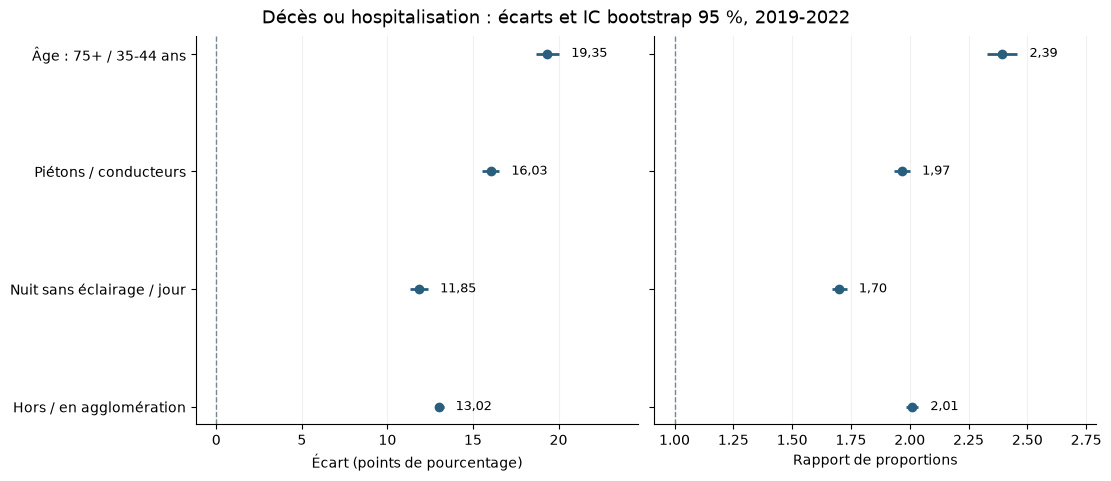

In [8]:
display(primary_results[["libellé", "n_A", "n_R", "proportion_A_pct", "proportion_R_pct"]].round(3))
display_intervals(primary_results)

def forest_plot(table, title, filename, color=BLUE):
    ordered = table.set_index("comparaison").loc[[spec["id"] for spec in COMPARISONS]]
    y = np.arange(len(ordered))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.7), sharey=True, constrained_layout=True)
    for ax, point, low, high, reference, xlabel in [
        (axes[0], "écart_points", "écart_ic_bas", "écart_ic_haut", 0, "Écart (points de pourcentage)"),
        (axes[1], "rapport", "rapport_ic_bas", "rapport_ic_haut", 1, "Rapport de proportions")]:
        ax.hlines(y, ordered[low], ordered[high], color=color, linewidth=2)
        ax.scatter(ordered[point], y, color=color, s=36, zorder=3)
        ax.axvline(reference, color=GREY, linestyle="--", linewidth=1)
        min_x = min(reference, float(ordered[low].min()))
        max_x = max(reference, float(ordered[high].max()))
        span = max(max_x-min_x, 0.2)
        ax.set_xlim(min_x-0.06*span, max_x+0.23*span)
        ax.set_xlabel(xlabel)
        ax.grid(axis="x", alpha=0.18)
        for yi, (_, row) in zip(y, ordered.iterrows()):
            ax.text(row[high]+0.035*span, yi, f"{row[point]:.2f}".replace(".", ","), va="center", fontsize=9)
    axes[0].set_yticks(y, [spec["libelle"] for spec in COMPARISONS])
    axes[0].invert_yaxis()
    axes[1].tick_params(labelleft=False)
    fig.suptitle(title, fontsize=13)
    finish_figure(fig, filename)

forest_plot(primary_results, "Décès ou hospitalisation : écarts et IC bootstrap 95 %, 2019-2022",
            "05_01_contrastes_cible_principale.png")


Les quatre écarts observés sont positifs : les proportions sont plus élevées chez les
75 ans ou plus que chez les 35-44 ans, chez les piétons que chez les conducteurs, de nuit
sans éclairage qu'en plein jour, et hors agglomération qu'en agglomération.

Pour les piétons et les conducteurs, l'écart est de **16,03 points**, avec un intervalle
bootstrap à 95 % d'environ **[15,52 ; 16,54] points**. Le rapport est proche de **1,97**,
avec un intervalle d'environ **[1,93 ; 2,00]**. Les quatre intervalles d'écart de l'analyse
regroupée restent au-dessus de zéro, dans le cadre de réplication adopté.

Les intervalles quantifient la variabilité sous notre schéma de réplication. Ils ne
mesurent pas les biais de collecte et ne rendent pas ces différences causales. Leur
étroitesse éventuelle ne suffit pas à établir la qualité des renseignements sources.
Les profils d'âge, de véhicule et de contexte peuvent contribuer ensemble aux écarts.


### Voir une distribution de réplications

L'histogramme suivant représente les 2 000 valeurs de l'écart piétons-conducteurs.
Il ne représente pas la distribution des blessures ni une population de 2 000 usagers.
Ses valeurs correspondent à 2 000 reconstructions statistiques de notre population
d'accidents, selon la méthode décrite plus haut.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


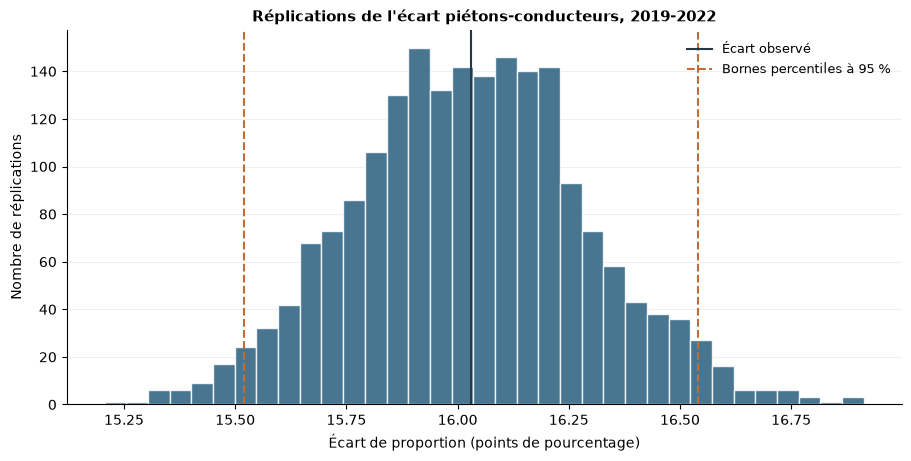

In [9]:
primary_rep_rates = event_rates(bootstrap_totals, EVENTS["deces_hospitalisation"])
pedestrian_differences = 100*(primary_rep_rates[:, GROUP_INDEX["pietons"]] - primary_rep_rates[:, GROUP_INDEX["conducteurs"]])
pedestrian_row = primary_results.set_index("comparaison").loc["usager"]
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
ax.hist(pedestrian_differences, bins=35, color=BLUE, alpha=0.85, edgecolor="white")
ax.axvline(pedestrian_row["écart_points"], color="#263746", linewidth=1.5, label="Écart observé")
ax.axvline(pedestrian_row["écart_ic_bas"], color=ORANGE, linestyle="--", linewidth=1.5, label="Bornes percentiles à 95 %")
ax.axvline(pedestrian_row["écart_ic_haut"], color=ORANGE, linestyle="--", linewidth=1.5)
ax.set(title="Réplications de l'écart piétons-conducteurs, 2019-2022",
       xlabel="Écart de proportion (points de pourcentage)", ylabel="Nombre de réplications")
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="y", alpha=0.18)
finish_figure(fig, "05_02_distribution_bootstrap_pietons.png")


### Vérifier la stabilité numérique des bornes

Un bootstrap utilise un nombre fini de tirages. Nous comparons les bornes obtenues avec
les 1 000 premières réplications à celles des 2 000 réplications, pour l'écart en points.
Cela évalue la sensibilité numérique au nombre de tirages sur cette exécution, sans
prouver la validité des hypothèses ni l'exactitude de la couverture à 95 %. Avec les
paramètres et les sources utilisés ici, la plus grande variation d'une borne d'écart
est d'environ 0,04 point de pourcentage.


In [10]:
half_results = pd.concat([contrast_results(observed_totals, bootstrap_totals[:B//2], event) for event in EVENTS], ignore_index=True)
stability = all_results[["comparaison", "événement", "écart_ic_bas", "écart_ic_haut"]].merge(
    half_results[["comparaison", "événement", "écart_ic_bas", "écart_ic_haut"]],
    on=["comparaison", "événement"], validate="one_to_one", suffixes=("_B", "_demi_B"))
stability["variation_max_borne_points"] = np.maximum(
    abs(stability["écart_ic_bas_B"]-stability["écart_ic_bas_demi_B"]),
    abs(stability["écart_ic_haut_B"]-stability["écart_ic_haut_demi_B"]))
display(stability.round(4))
print(f"Plus grande variation d'une borne : {stability['variation_max_borne_points'].max():.4f} point(s).")


,comparaison,événement,écart_ic_bas_B,écart_ic_haut_B,écart_ic_bas_demi_B,écart_ic_haut_demi_B,variation_max_borne_points
0,age,deces_hospitalisation,18.6885,20.0401,18.6534,20.0205,0.0350
1,usager,deces_hospitalisation,15.5194,16.5409,15.5312,16.5334,0.0118
2,lumiere,deces_hospitalisation,11.3470,12.3782,11.3309,12.3653,0.0161
3,agglomeration,deces_hospitalisation,12.7580,13.2847,12.7548,13.2798,0.0048
4,age,deces_seul,6.0632,6.8413,6.0325,6.8374,0.0307
5,usager,deces_seul,2.1638,2.6329,2.1638,2.6360,0.0031
6,lumiere,deces_seul,3.8716,4.3734,3.8607,4.3753,0.0109
7,agglomeration,deces_seul,3.1507,3.3788,3.1506,3.3743,0.0045


Plus grande variation d'une borne : 0.0350 point(s).


## 5. Refaire les comparaisons séparément par année

Le regroupement des années peut masquer des différences. Pour chaque année, nous
recalculons les proportions, les écarts et les rapports. Les intervalles utilisent les
réplications de cette seule année, déjà calculées lors du bootstrap stratifié.
Cette lecture reste conditionnelle aux années observées et ne prédit pas l'année suivante.


,année,libellé,n_A,n_R,proportion_A_pct,proportion_R_pct,écart_points
0,2019,Âge : 75+ / 35-44 ans,6391,20211,34.38,13.67,20.71
1,2019,Piétons / conducteurs,10679,92748,33.16,16.78,16.38
2,2019,Nuit sans éclairage / jour,12776,84494,29.27,17.17,12.10
3,2019,Hors / en agglomération,47464,78888,26.25,13.17,13.08
8,2020,Âge : 75+ / 35-44 ans,4550,15825,35.23,14.19,21.04
9,2020,Piétons / conducteurs,7796,73847,33.80,17.09,16.71
10,2020,Nuit sans éclairage / jour,9637,66480,29.76,17.33,12.43
11,2020,Hors / en agglomération,36888,62281,26.42,13.48,12.95
16,2021,Âge : 75+ / 35-44 ans,5477,18746,31.64,13.47,18.17
17,2021,Piétons / conducteurs,8981,92169,31.68,15.85,15.83


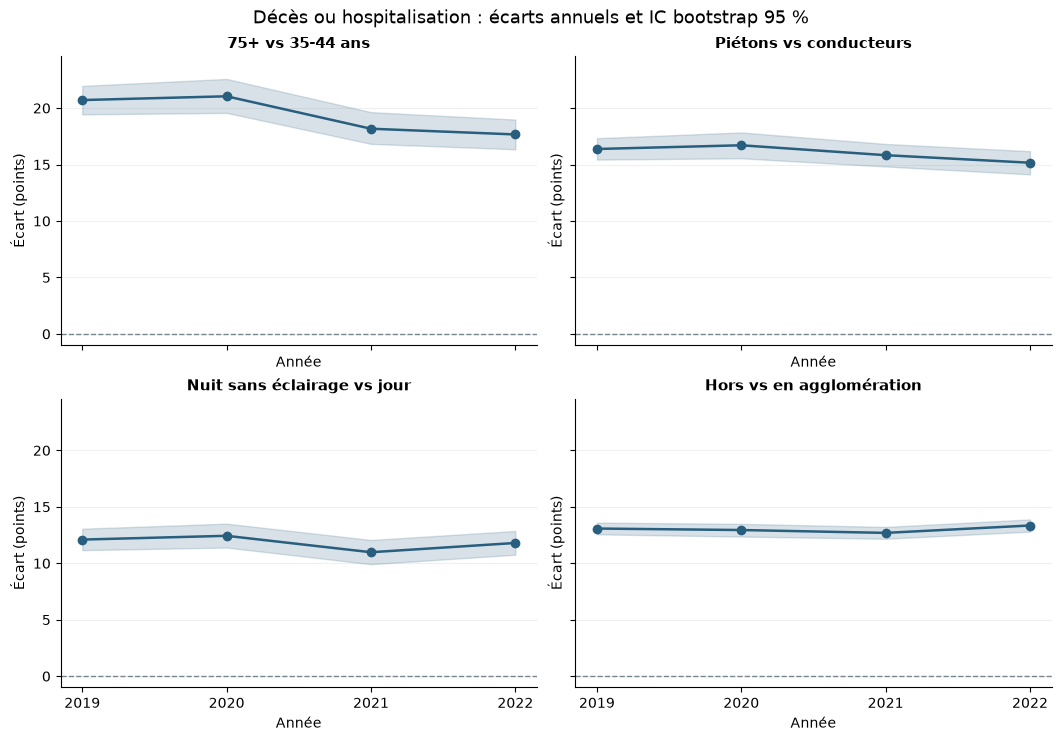

In [11]:
annual_parts = []
for year in TRAIN_YEARS:
    observed_year = counts_by_year[year].sum(axis=0)
    for event in EVENTS:
        result = contrast_results(observed_year, bootstrap_by_year[year], event)
        result["année"] = year
        annual_parts.append(result)
annual_results = pd.concat(annual_parts, ignore_index=True)
annual_primary = annual_results.loc[annual_results["événement"].eq("deces_hospitalisation")].copy()
display(annual_primary[["année", "libellé", "n_A", "n_R", "proportion_A_pct", "proportion_R_pct", "écart_points"]].round(2))

fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.3), sharex=True, sharey=True, constrained_layout=True)
for ax, spec in zip(axes.ravel(), COMPARISONS):
    frame = annual_primary.loc[annual_primary["comparaison"].eq(spec["id"])].sort_values("année")
    years = frame["année"].to_numpy(dtype=int)
    ax.plot(years, frame["écart_points"].to_numpy(dtype=float), color=BLUE, marker="o", linewidth=1.8)
    ax.fill_between(years, frame["écart_ic_bas"].to_numpy(dtype=float), frame["écart_ic_haut"].to_numpy(dtype=float), color=BLUE, alpha=0.18)
    ax.axhline(0, color=GREY, linestyle="--", linewidth=1)
    ax.set(title=spec["titre"], xlabel="Année", ylabel="Écart (points)")
    ax.set_xticks(TRAIN_YEARS)
    ax.grid(axis="y", alpha=0.18)
axes[0, 0].set_ylim(min(0, float(annual_primary["écart_ic_bas"].min()))-1,
                    float(annual_primary["écart_ic_haut"].max())+2)
fig.suptitle("Décès ou hospitalisation : écarts annuels et IC bootstrap 95 %", fontsize=13)
finish_figure(fig, "05_03_contrastes_annuels.png")


Le sens des quatre écarts reste le même dans chacune des années : les groupes A présentent
une proportion plus élevée que leur référence. L'écart entre les 75 ans ou plus et les
35-44 ans est cependant plus faible en 2021-2022 qu'en 2019-2020 dans ces données.
Nous n'en déduisons pas un effet du temps à partir du seul graphique.

Même lorsqu'une différence est présente chaque année, elle peut encore refléter des
compositions différentes des groupes. Une constance annuelle n'est donc pas un ajustement
sur les autres caractéristiques.

Les bandes représentent des intervalles marginaux pour chaque année. Elles ne constituent
ni une bande simultanée ni un intervalle de prévision pour 2023 ou 2024.


## 6. Examiner la sensibilité aux décès seuls

Nous gardons exactement les mêmes groupes et les mêmes gravités connues, mais nous
changeons l'événement : seuls les décès comptent maintenant comme positifs. Les blessés
hospitalisés et légers, ainsi que les indemnes, comptent comme négatifs pour cette analyse.

Le changement de fréquence de l'événement modifie l'échelle des écarts. Un écart absolu
plus petit peut coexister avec un rapport plus grand : les deux mesures doivent être lues
ensemble. Nous utilisons les mêmes tirages d'accidents pour les deux événements.


,libellé,n_A,n_R,proportion_A_pct,proportion_R_pct
4,Âge : 75+ / 35-44 ans,22418,73461,8.408,1.967
5,Piétons / conducteurs,36526,347962,4.846,2.452
6,Nuit sans éclairage / jour,45404,316041,6.319,2.200
7,Hors / en agglomération,175858,291221,4.604,1.339


,libellé,écart_points,rapport,IC_95_écart,IC_95_rapport
4,Âge : 75+ / 35-44 ans,6.44,4.275,[6.06 ; 6.84],[4.00 ; 4.61]
5,Piétons / conducteurs,2.39,1.976,[2.16 ; 2.63],[1.88 ; 2.08]
6,Nuit sans éclairage / jour,4.12,2.873,[3.87 ; 4.37],[2.74 ; 3.01]
7,Hors / en agglomération,3.27,3.439,[3.15 ; 3.38],[3.30 ; 3.58]


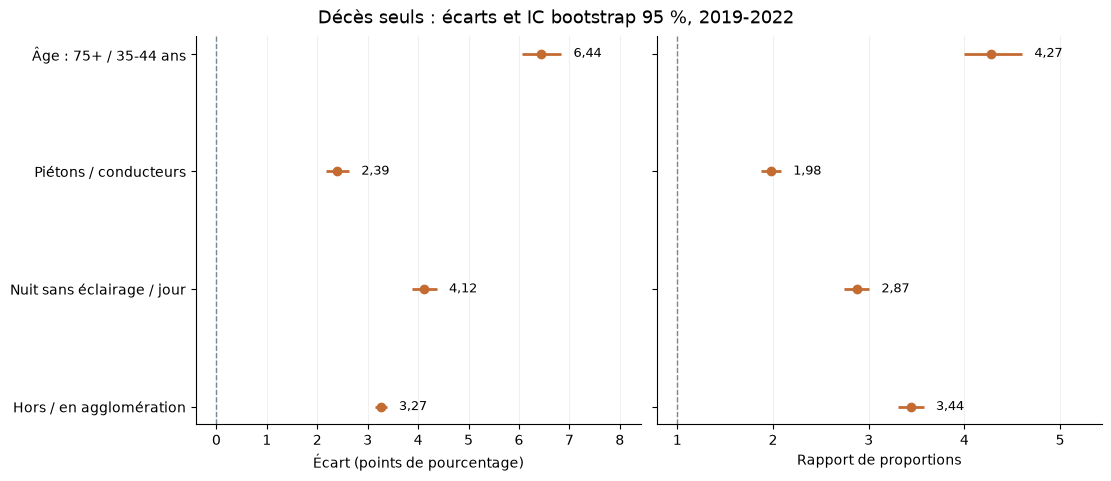

,comparaison,libellé,écart_points_cible_principale,rapport_cible_principale,écart_points_décès_seuls,rapport_décès_seuls
0,age,Âge : 75+ / 35-44 ans,19.349,2.390,6.441,4.275
1,usager,Piétons / conducteurs,16.029,1.967,2.394,1.976
2,lumiere,Nuit sans éclairage / jour,11.848,1.699,4.119,2.873
3,agglomeration,Hors / en agglomération,13.019,2.010,3.265,3.439


In [12]:
display(death_results[["libellé", "n_A", "n_R", "proportion_A_pct", "proportion_R_pct"]].round(3))
display_intervals(death_results)
forest_plot(death_results, "Décès seuls : écarts et IC bootstrap 95 %, 2019-2022",
            "05_04_contrastes_deces_seuls.png", color=ORANGE)

sensitivity = primary_results[["comparaison", "libellé", "écart_points", "rapport"]].merge(
    death_results[["comparaison", "écart_points", "rapport"]], on="comparaison", validate="one_to_one",
    suffixes=("_cible_principale", "_décès_seuls"))
display(sensitivity.round(3))


Les décès seuls représentent environ **2,57 %** des gravités connues, contre 17,8 % pour
le regroupement principal. Les écarts absolus sont donc à lire sur une autre échelle.

Pour l'âge, par exemple, les proportions de décès sont d'environ **8,41 % chez les 75 ans
ou plus** et **1,97 % chez les 35-44 ans**. L'écart est de 6,44 points et le rapport d'environ
4,27. Le regroupement avec les hospitalisations donnait un rapport proche de 2,39.

Pour la lumière et l'agglomération, les rapports observés sont également plus élevés avec
les décès seuls. Le rapport piétons-conducteurs reste proche de deux. Ces résultats montrent
que le choix de cible change l'interprétation quantitative ; ils ne permettent pas de
choisir une définition parce qu'elle produit le contraste le plus spectaculaire.


## 7. Vérifier les résultats et conserver la méthode

Les vérifications suivantes rapprochent les comptages par accident des proportions
calculées directement par usager. Elles contrôlent la fréquence des décès, la population
retenue et le nombre de réplications exploitables. Le fichier préparé doit rester inchangé.


In [13]:
assert set(counts_by_year) == set(TRAIN_YEARS)
assert cluster_overview["accidents"].sum() == int(overview["accidents"])
assert np.array_equal(bootstrap_totals, sum(bootstrap_by_year.values()))
observed_cube = observed_totals.reshape(len(GROUPS), 3)
for i, name in enumerate(GROUPS):
    assert observed_cube[i, 0] == group_points.loc[name, "gravités_connues"]
    assert observed_cube[i, 1] == group_points.loc[name, "positifs_principaux"]
    assert observed_cube[i, 2] == group_points.loc[name, "décès"]
for table in [all_results, annual_results]:
    assert table["n_A"].gt(0).all() and table["n_R"].gt(0).all()
    assert table[["réplications_valides_écart", "réplications_valides_rapport"]].eq(B).all().all()
    assert table["écart_ic_bas"].le(table["écart_ic_haut"]).all()
    assert table["rapport_ic_bas"].le(table["rapport_ic_haut"]).all()
assert data["deces_seul"].notna().sum() == data[PRIMARY].notna().sum()
assert file_sha256(DATA_PATH) == input_sha256
print("Contrôles validés : comptages, période, définition des cibles, réplications et source inchangée.")


Contrôles validés : comptages, période, définition des cibles, réplications et source inchangée.


In [14]:
group_interval_rows = []
replica_tables = []
for event, event_index in EVENTS.items():
    rates = event_rates(bootstrap_totals, event_index)
    observed_rates = event_rates(observed_totals, event_index)[0]
    for i, name in enumerate(GROUPS):
        low, high, valid = interval95(100*rates[:, i])
        group_interval_rows.append({"groupe": name, "libellé": GROUP_LABELS[name], "événement": event,
            "gravités_connues": int(observed_cube[i, 0]), "positifs": int(observed_cube[i, event_index]),
            "proportion_pct": 100*observed_rates[i], "ic_bas_pct": low, "ic_haut_pct": high,
            "réplications_valides": valid})
    for spec in COMPARISONS:
        a, r = GROUP_INDEX[spec["a"]], GROUP_INDEX[spec["r"]]
        replica_tables.append(pd.DataFrame({"réplication": np.arange(1, B+1),
            "comparaison": spec["id"], "événement": event,
            "proportion_A": rates[:, a], "proportion_R": rates[:, r],
            "écart_points": 100*(rates[:, a]-rates[:, r]), "rapport": safe_divide(rates[:, a], rates[:, r])}))
group_intervals = pd.DataFrame(group_interval_rows)
replicas_export = pd.concat(replica_tables, ignore_index=True)

if EXPORT_RESULTS:
    for name, table in {"comptages_groupes": group_points.reset_index(),
        "intervalles_groupes": group_intervals, "contrastes": all_results,
        "comparaisons_annuelles": annual_results, "sensibilite_cible": sensitivity,
        "stabilite_bootstrap": stability, "accidents_par_annee": cluster_overview.reset_index()}.items():
        table.to_csv(TABLE_DIR / f"05_{name}.csv", index=False, encoding="utf-8", na_rep=schema["marqueur_na_csv"])
    replicas_export.to_csv(TABLE_DIR / "05_replicats_contrastes.csv.gz", index=False, encoding="utf-8",
                          compression="gzip", na_rep=schema["marqueur_na_csv"])
    metadata = {"notebook": "05_statistical_probability_analysis.ipynb", "années": TRAIN_YEARS,
        "population": "usagers BAAC métropole, Corse comprise ; proportions sur gravités connues",
        "usagers": len(data), "gravités_connues": int(known.sum()), "gravités_inconnues": int((~known).sum()),
        "accidents": len(cluster_counts), "fichier_préparé": DATA_PATH.relative_to(PROJECT_ROOT).as_posix(),
        "sha256_fichier_préparé": input_sha256, "B": B, "graine": SEED,
        "générateur": "numpy.default_rng(SeedSequence([graine, année]))",
        "rééchantillonnage": "accidents entiers avec remise, séparément dans chaque année ; nombre d'accidents fixe",
        "groupes": GROUP_LABELS, "comparaisons": COMPARISONS,
        "cible_principale": {"1": [2, 3], "0": [1, 4]}, "décès_seuls": {"1": [2], "0": [1, 3, 4]},
        "IC": {"méthode": "percentile", "niveau_nominal": 0.95, "quantiles": [0.025, 0.975],
               "interpolation_numpy": "linear", "couverture": "marginale, conditionnelle aux hypothèses",
               "réplication_indéfinie": "intervalle manquant et nombre de valeurs valides signalé"},
        "hypothèses": ["accidents approximativement indépendants au sein d'une année",
                        "distribution empirique comme approximation du processus d'enregistrement", "années fixes"],
        "limites": ["comparaisons exploratoires sélectionnées après EDA", "absence d'ajustement sur les autres variables",
                    "pas de correction des erreurs de saisie ou de sous-déclaration", "pas de garantie de couverture simultanée",
                    "pas de modélisation de dépendance spatiale ou temporelle supplémentaire", "pas d'inférence causale"],
        "python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
        "figures": figure_names,
        "références": ["https://www.stata.com/manuals/rbsample.pdf",
                       "https://www.stata.com/support/faqs/statistics/bootstrap-with-panel-data/",
                       "https://itl.nist.gov/div898/handbook/eda/section3/eda334.htm"]}
    (TABLE_DIR / "05_metadonnees_statistiques.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2)+"\n", encoding="utf-8")
    print("Tableaux, réplications et méthode enregistrés dans reports/tables/ ; figures dans reports/figures/.")


Tableaux, réplications et méthode enregistrés dans reports/tables/ ; figures dans reports/figures/.


### Références de méthode

Le rééchantillonnage avec remise de groupes entiers et la sélection séparée au sein de
strates sont décrits dans le manuel [Stata, bsample](https://www.stata.com/manuals/rbsample.pdf).
La [FAQ de Stata sur les données regroupées](https://www.stata.com/support/faqs/statistics/bootstrap-with-panel-data/)
illustre la conservation des groupes et de leurs sélections répétées. Le
[manuel NIST sur le bootstrap](https://itl.nist.gov/div898/handbook/eda/section3/eda334.htm)
présente la distribution des réplications et la construction d'intervalles par percentiles.

Nous appliquons ces principes en Python. Le choix de l'accident comme groupe, de l'année
comme strate et les hypothèses sur le processus BAAC relèvent de notre protocole ; ces
références ne valident pas à elles seules leur pertinence pour toutes les analyses du fichier.

## 8. Conclusion

Nous avons transformé les différences descriptives en écarts absolus et rapports de
proportions, puis quantifié leur variabilité par un bootstrap qui conserve les usagers
d'un même accident. La lecture annuelle et l'analyse des décès seuls complètent la cible
principale. Les résultats montrent que la taille d'une association dépend aussi de la
définition de l'événement étudié.

Les intervalles ne corrigent pas les limites de collecte et les comparaisons restent
brutes : l'âge, la catégorie d'usager et le contexte peuvent se recouper. Les résultats
ne constituent ni des effets causaux ni une mesure du risque par trajet. Les analyses
précédentes ont aussi montré que l'âge inconnu est associé à une répartition particulière
de gravité ; cette information demandera un traitement explicite lors de la modélisation.

**La prochaine étape est de définir la régression logistique et son protocole d'évaluation.**
Nous préciserons les variables disponibles, le traitement des valeurs manquantes, les
références et la manière de distinguer interprétation des associations et performance
prédictive, en conservant la validation sur 2023 et le test final sur 2024.
